# 04 · Ajuste de hiperparámetros de los 3 mejores candidatos

**Método: `RandomizedSearchCV` con 30 configuraciones por modelo**, usando el mismo `StratifiedKFold(5)` y la misma métrica (AUC-ROC). Lo elijo por tres razones:
1. Con un presupuesto fijo de 30 configuraciones, la búsqueda aleatoria cubre mejor que una grilla los espacios continuos en escala logarítmica, como la tasa de aprendizaje y la regularización.
2. Usa exactamente el mismo objeto de CV y el mismo pipeline que la fase de candidatos, así que la comparación es directa.
3. Devuelve todas las configuraciones evaluadas (`cv_results_`), que se registran tal cual como corridas hijas.

Optuna (TPE) aporta poco con solo 30 intentos por modelo y agrega una dependencia más.

Los 3 modelos se leen **desde MLflow** (fase `candidato`, ordenados por AUC media en CV), no se escriben a mano.

In [1]:
import sys, time, warnings
sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, mlflow
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from src.datos import cargar_obt, dividir, esquema_cv, SEMILLA
from src.pipeline import construir_pipeline
from src import tracking
sns.set_theme(style='whitegrid'); IMG = '../docs/img/'
tracking.configurar(); exp = mlflow.get_experiment_by_name(tracking.EXPERIMENTO)
obt, meta = cargar_obt(); X_train, X_test, y_train, y_test = dividir(obt); cols = list(X_train.columns)
cand = mlflow.search_runs([exp.experiment_id], filter_string="tags.fase = 'candidato'", order_by=['metrics.cv_roc_auc_mean DESC'])
cand = cand[cand['tags.familia'] != 'sota_llm']
top3 = cand.head(3)[['tags.modelo','tags.familia','metrics.cv_roc_auc_mean','metrics.cv_roc_auc_std','run_id']]
top3

,tags.modelo,tags.familia,metrics.cv_roc_auc_mean,metrics.cv_roc_auc_std,run_id
0,hist_gradient_boosting,boosting,0.784219,0.004398,ec817b29f81e405e997f3076ac97cef5
1,lightgbm,boosting,0.782224,0.006837,69b7cc89110a4cc9836643a1a8562763
2,logistic_regression,lineal_regularizado,0.780563,0.006587,ffb1a69cbf364dac8a49ae6cd8efe111


## Espacios de búsqueda

| Modelo | Hiperparámetro | Rango | Escala y motivo |
|---|---|---|---|
| HistGB / LightGBM / XGBoost | `learning_rate` | 0,01 – 0,3 | **log**: el efecto es multiplicativo; 0,01→0,02 importa tanto como 0,1→0,2 |
| | iteraciones (`max_iter` / `n_estimators`) | 100 – 800/1000 | lineal; compensa las tasas de aprendizaje bajas |
| | complejidad del árbol (`max_leaf_nodes` / `num_leaves` / `max_depth`) | 8 – 128 hojas | lineal; el default (31) está en el centro |
| | mínimo por hoja | 10/20 – 300 | lineal; regulariza frente a la brecha observada en los candidatos |
| | `l2` / `reg_lambda` / `reg_alpha` | 1e-4 – 10 | **log**: abarca 5 órdenes de magnitud |
| | submuestreo de filas/columnas | 0,4 – 1,0 | lineal; bagging interno para reducir la varianza |
| Regresión logística | `C` | 1e-4 – 100 | **log**: es el inverso de la regularización |
| | `penalty` | l1, l2 | categórica (liblinear soporta ambas) |
| | `class_weight` | None, balanced | categórica (hallazgo H1: desbalance) |

In [2]:
ESPACIOS = {
 'hist_gradient_boosting': (HistGradientBoostingClassifier(random_state=SEMILLA), {
     'modelo__learning_rate': loguniform(0.01, 0.3), 'modelo__max_iter': randint(100, 800),
     'modelo__max_leaf_nodes': randint(8, 64), 'modelo__min_samples_leaf': randint(20, 300),
     'modelo__l2_regularization': loguniform(1e-4, 10), 'modelo__max_features': uniform(0.4, 0.6)}),
 'lightgbm': (LGBMClassifier(random_state=SEMILLA, verbose=-1, n_jobs=1, subsample_freq=1), {
     'modelo__learning_rate': loguniform(0.01, 0.3), 'modelo__n_estimators': randint(100, 1000),
     'modelo__num_leaves': randint(8, 128), 'modelo__min_child_samples': randint(10, 300),
     'modelo__subsample': uniform(0.5, 0.5), 'modelo__colsample_bytree': uniform(0.4, 0.6),
     'modelo__reg_lambda': loguniform(1e-4, 10), 'modelo__reg_alpha': loguniform(1e-4, 10)}),
 'logistic_regression': (LogisticRegression(solver='liblinear', max_iter=2000, random_state=SEMILLA), {
     'modelo__C': loguniform(1e-4, 1e2), 'modelo__penalty': ['l1', 'l2'], 'modelo__class_weight': [None, 'balanced']}),
 'xgboost': (XGBClassifier(random_state=SEMILLA, n_jobs=1, eval_metric='logloss'), {
     'modelo__learning_rate': loguniform(0.01, 0.3), 'modelo__n_estimators': randint(100, 800),
     'modelo__max_depth': randint(2, 8), 'modelo__min_child_weight': loguniform(1, 50),
     'modelo__subsample': uniform(0.5, 0.5), 'modelo__colsample_bytree': uniform(0.4, 0.6), 'modelo__reg_lambda': loguniform(1e-3, 10)}),
 'random_forest': (RandomForestClassifier(random_state=SEMILLA, n_jobs=1), {
     'modelo__n_estimators': randint(100, 500), 'modelo__max_depth': [None, 6, 8, 10, 12, 16, 20],
     'modelo__min_samples_leaf': randint(1, 50), 'modelo__max_features': uniform(0.1, 0.5)}),
 'mlp': (MLPClassifier(random_state=SEMILLA, early_stopping=True, max_iter=300), {
     'modelo__hidden_layer_sizes': [(32,), (64,), (128,), (64, 32), (128, 64)], 'modelo__alpha': loguniform(1e-5, 1e-1),
     'modelo__learning_rate_init': loguniform(1e-4, 1e-2), 'modelo__batch_size': [128, 256, 512]}),
}
N_ITER = 30

## Búsqueda: corrida padre por modelo y una corrida hija por configuración

In [3]:
resumen, detalle = [], {}
for _, fila in top3.iterrows():
    nombre, familia = fila['tags.modelo'], fila['tags.familia']
    modelo, espacio = ESPACIOS[nombre]
    busqueda = RandomizedSearchCV(construir_pipeline(modelo, cols), espacio, n_iter=N_ITER, cv=esquema_cv(),
                                  scoring=tracking.SCORING, refit='roc_auc', return_train_score=True,
                                  random_state=SEMILLA, n_jobs=-1)
    with mlflow.start_run(run_name=f'tuning_{nombre}') as padre:
        mlflow.set_tags({'fase': 'tuning', 'familia': familia, 'modelo': nombre, 'git_commit': tracking.commit_git()})
        tracking.log_datos(meta)
        mlflow.log_params({'metodo': 'RandomizedSearchCV', 'n_iter': N_ITER, 'semilla': SEMILLA,
                           'cv': 'StratifiedKFold(5, shuffle, 42)', 'espacio': str({k: str(v) for k, v in espacio.items()})[:500]})
        t0 = time.perf_counter(); busqueda.fit(X_train, y_train); seg = time.perf_counter() - t0
        cvr = pd.DataFrame(busqueda.cv_results_)
        for i, r in cvr.iterrows():                                   # corridas hijas
            with mlflow.start_run(run_name=f'{nombre}_cfg{i:02d}', nested=True):
                mlflow.set_tags({'fase': 'tuning_config', 'familia': familia, 'modelo': nombre, 'git_commit': tracking.commit_git()})
                mlflow.log_params({k.replace('modelo__', 'hp_'): str(v) for k, v in r['params'].items()})
                mlflow.log_metrics({'cv_roc_auc_mean': r.mean_test_roc_auc, 'cv_roc_auc_std': r.std_test_roc_auc,
                                    'train_roc_auc': r.mean_train_roc_auc, 'brecha_roc_auc': r.mean_train_roc_auc - r.mean_test_roc_auc,
                                    'cv_average_precision_mean': r.mean_test_average_precision, 'fit_seconds_mean': r.mean_fit_time})
        b = cvr.loc[busqueda.best_index_]
        mejora = b.mean_test_roc_auc - fila['metrics.cv_roc_auc_mean']
        umbral_ruido = max(b.std_test_roc_auc, fila['metrics.cv_roc_auc_std'])
        metricas = {'cv_roc_auc_mean': b.mean_test_roc_auc, 'cv_roc_auc_std': b.std_test_roc_auc, 'train_roc_auc': b.mean_train_roc_auc,
                    'brecha_roc_auc': b.mean_train_roc_auc - b.mean_test_roc_auc, 'cv_average_precision_mean': b.mean_test_average_precision,
                    'cv_average_precision_std': b.std_test_average_precision, 'fit_seconds_mean': b.mean_fit_time,
                    'default_cv_roc_auc_mean': fila['metrics.cv_roc_auc_mean'], 'mejora_vs_default': mejora,
                    'mejora_supera_desv': float(mejora > umbral_ruido), 'busqueda_seconds': seg}
        mlflow.log_metrics(metricas)
        mlflow.log_params({k.replace('modelo__', 'best_'): str(v) for k, v in busqueda.best_params_.items()})
        tracking.log_modelo(busqueda.best_estimator_, X_train)
        cvr.drop(columns='params').to_csv(f'../docs/tuning_{nombre}.csv', index=False); mlflow.log_artifact(f'../docs/tuning_{nombre}.csv')
    detalle[nombre] = cvr
    resumen.append({'modelo': nombre, 'default_cv_auc': fila['metrics.cv_roc_auc_mean'], 'default_std': fila['metrics.cv_roc_auc_std'],
                    'tuned_cv_auc': b.mean_test_roc_auc, 'tuned_std': b.std_test_roc_auc, 'mejora': mejora,
                    'mejora_supera_desv': mejora > umbral_ruido, 'tuned_train_auc': b.mean_train_roc_auc,
                    'brecha_tuned': b.mean_train_roc_auc - b.mean_test_roc_auc, 'n_configs': len(cvr), 'segundos': seg,
                    'best_params': busqueda.best_params_, 'run_id': padre.info.run_id})
    print(f"{nombre:24s} default {fila['metrics.cv_roc_auc_mean']:.4f} -> tuned {b.mean_test_roc_auc:.4f} ± {b.std_test_roc_auc:.4f} (mejora {mejora:+.4f}; ruido {umbral_ruido:.4f}) en {seg:.0f}s")

2026/11/18 20:13:33 INFO mlflow.tracking._tracking_service.client: 🏃 View run hist_gradient_boosting_cfg00 at: http://localhost:5001/#/experiments/1/runs/e7115fce150d432cbddcc28f9bef9751.


2026/11/18 20:13:33 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5001/#/experiments/1.


2026/11/18 20:13:33 INFO mlflow.tracking._tracking_service.client: 🏃 View run hist_gradient_boosting_cfg01 at: http://localhost:5001/#/experiments/1/runs/215d22d996994f0bada67f409749fc7a.


2026/11/18 20:13:33 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5001/#/experiments/1.


2026/11/18 20:13:33 INFO mlflow.tracking._tracking_service.client: 🏃 View run hist_gradient_boosting_cfg02 at: http://localhost:5001/#/experiments/1/runs/011b8a7e48374cbca15bbb1a7fb2c791.


2026/11/18 20:13:33 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5001/#/experiments/1.


... (182 outputs left out)

2026/11/18 20:16:27 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 20:16:27 INFO mlflow.tracking._tracking_service.client: 🏃 View run tuning_logistic_regression at: http://localhost:5001/#/experiments/1/runs/a96ee950de3e408e9a83b120c98bdf8f.


2026/11/18 20:16:27 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5001/#/experiments/1.


logistic_regression      default 0.7806 -> tuned 0.7815 ± 0.0059 (mejora +0.0009; ruido 0.0066) en 28s


## Resultados del tuning

In [4]:
res = pd.DataFrame(resumen); res.drop(columns='best_params').to_csv('../docs/resultados_tuning.csv', index=False)
pd.set_option('display.max_colwidth', 120); res.round(4)

,modelo,default_cv_auc,default_std,tuned_cv_auc,tuned_std,mejora,mejora_supera_desv,tuned_train_auc,brecha_tuned,n_configs,segundos,best_params,run_id
0,hist_gradient_boosting,0.7842,0.0044,0.7873,0.0041,0.0031,False,0.8328,0.0455,30,38.6209,"{'modelo__l2_regularization': 0.4061136676690665, 'modelo__learning_rate': 0.022314046859113604, 'modelo__max_featur...",207f2304a38841f6bc0a3e63113d582f
1,lightgbm,0.7822,0.0068,0.7870,0.0044,0.0047,False,0.8292,0.0423,30,112.2409,"{'modelo__colsample_bytree': 0.9295818059136038, 'modelo__learning_rate': 0.018999548501132082, 'modelo__min_child_s...",97be9181f5a84fcf9f0e3cd795c73969
2,logistic_regression,0.7806,0.0066,0.7815,0.0059,0.0009,False,0.7865,0.0050,30,27.9507,"{'modelo__C': 43.35045392775134, 'modelo__class_weight': 'balanced', 'modelo__penalty': 'l2'}",a96ee950de3e408e9a83b120c98bdf8f


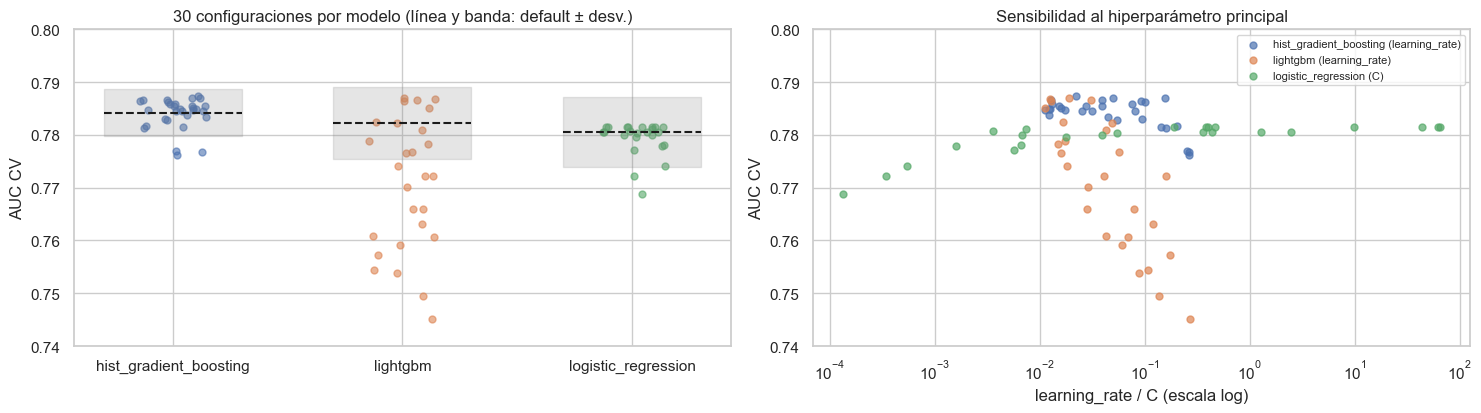

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
for k, (nombre, cvr) in enumerate(detalle.items()):
    x = np.full(len(cvr), k) + np.random.RandomState(0).uniform(-.15, .15, len(cvr))
    ax[0].scatter(x, cvr.mean_test_roc_auc, alpha=.6, s=25)
    d = res.set_index('modelo').loc[nombre]
    ax[0].hlines(d.default_cv_auc, k-.3, k+.3, colors='k', linestyles='--'); ax[0].fill_between([k-.3, k+.3], d.default_cv_auc-d.default_std, d.default_cv_auc+d.default_std, color='gray', alpha=.2)
ax[0].set_xticks(range(len(detalle))); ax[0].set_xticklabels(list(detalle)); ax[0].set_ylabel('AUC CV'); ax[0].set_title('30 configuraciones por modelo (línea y banda: default ± desv.)')
ax[0].set_ylim(0.74, 0.80)
for nombre, cvr in detalle.items():
    p = 'param_modelo__learning_rate' if 'param_modelo__learning_rate' in cvr else 'param_modelo__C'
    ax[1].scatter(cvr[p].astype(float), cvr.mean_test_roc_auc, label=f"{nombre} ({p.split('__')[1]})", alpha=.7, s=25)
ax[1].set_xscale('log'); ax[1].set_xlabel('learning_rate / C (escala log)'); ax[1].set_ylabel('AUC CV'); ax[1].set_ylim(0.74, 0.80); ax[1].legend(fontsize=8); ax[1].set_title('Sensibilidad al hiperparámetro principal')
plt.tight_layout(); plt.savefig(IMG+'tuning.png', dpi=150); plt.show()

**Criterio de mejora:** el ajuste solo cuenta como mejora si la ganancia en AUC media supera la desviación entre pliegues (columna `mejora_supera_desv`). Si no la supera, el modelo ajustado y el default son estadísticamente indistinguibles con esta CV, y lo documento como tal.